## Multimodal RAG, GraphRAG i vectorless RAG (PageIndex)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/pl/7_5_Multimodal_graph_vectorless_RAG.ipynb)

| | |
|---|---|
| 🎯 **Czego się nauczysz** | Trzy wzorce RAG wykraczające poza „chunk + embedding + top-k”: Docling i multimodalny RAG na tabelach i wykresach, GraphRAG na grafie powiązań spółek (agent na networkx oraz Neo4j + Cypher) i bezwektorowy RAG nawigujący po drzewie dokumentu w stylu PageIndex. |
| 🔑 **Klucze API** | `OPENAI_API_KEY`; opcjonalnie `NEO4J_URI`, `NEO4J_USERNAME`, `NEO4J_PASSWORD` |
| 💲 **Koszt API** | niski – około 20 krótkich zapytań, w tym dwa z obrazem |
| ⏱️ **Czas wykonania** | 2–4 min (pierwsze uruchomienie Doclinga pobiera modele analizy układu strony) |

Klasyczny RAG dzieli tekst na fragmenty, zamienia je na embeddingi i zwraca te najbardziej *podobne*. Sprawdza się, gdy odpowiedź znajduje się w jednym akapicie zwykłego tekstu. Ma problem, gdy:

| Problem | Przykład | Wzorzec z tego notebooka |
|---|---|---|
| odpowiedź jest w **tabeli, na wykresie lub skanie** | „W którym kwartale marża EBITDA była najniższa?” (wartość jest tylko na wykresie) | **Docling + multimodalny RAG**, ColPali |
| odpowiedź wymaga **analizy relacji między wieloma dokumentami** | „Które spółki są pośrednio powiązane z osobą X poprzez wspólnych udziałowców?” | **GraphRAG**, Neo4j + Cypher |
| dokument jest **długi i dobrze ustrukturyzowany**, a wyszukiwanie podobieństwa zwraca fragmenty bez kontekstu | raporty finansowe i prawne, prospekty emisyjne | **vectorless RAG** (PageIndex) |

Wszystkie trzy części korzystają z jednego syntetycznego zbioru danych: raportu rocznego fikcyjnej spółki *Nordwind Logistics S.A.* i sieci jej powiązań właścicielskich.

### Instalacja bibliotek

In [1]:
# Zainstaluj bezpośrednie zależności używane w tym notebooku.
# Pomijane, gdy brak pip, np. w środowisku `uv sync`, które ma je już zainstalowane (zob. README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langchain langchain-openai langchain-text-splitters langchain-neo4j docling networkx reportlab matplotlib pandas python-dotenv
# Google Colab: dodaj OPENAI_API_KEY w panelu Secrets (🔑) i nadaj temu notebookowi dostęp.
# Odkomentuj poniższe linie, aby wczytać klucz z Colab Secrets do tego środowiska:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Lokalnie wpisz OPENAI_API_KEY=... do pliku .env; nie commituj klucza.

Note: you may need to restart the kernel to use updated packages.


### Modele

In [23]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

load_dotenv()

llm = ChatOpenAI(model="gpt-6.1-terra", reasoning_effort="none", temperature=0)  # multimodal: text + images
embeddings = OpenAIEmbeddings()

### Dane przykładowe: raport roczny w PDF

PDF generujemy sami, dzięki czemu notebook nie potrzebuje zewnętrznych plików. Celowo łączy on trzy rodzaje treści:
- **tekst** z numerowaną hierarchią nagłówków (wykorzystamy ją w PageIndex),
- **tabelę** przychodów w podziale na segmenty,
- **wykres**, którego kwartalne wartości *nie występują* nigdzie w tekście – pytania o nie obsłuży tylko model rozumiejący obrazy.

In [3]:
REPORT = {
    "title": "Nordwind Logistics S.A. – Raport roczny 2025",
    "sections": [
        ("1. Informacje o przedsiębiorstwie",
         "Nordwind Logistics S.A. to grupa logistyczna z siedzibą w Gdańsku, założona w 2009 roku. Prowadzi transport "
         "drogowy, spedycję morską i magazynowanie kontraktowe w Polsce, Niemczech i krajach bałtyckich. "
         "Na koniec 2025 roku grupa zatrudniała 2340 osób i dysponowała flotą 610 ciągników siodłowych."),
        ("2. Wyniki finansowe",
         "W 2025 roku przychody wzrosły o 4,4% do 802 mln zł, a zysk netto spadł do 31 mln zł "
         "(2024: 38 mln zł) z powodu wyższych kosztów osobowych i paliwa."),
        ("2.1. Przychody",
         "Wzrost zapewniły transport drogowy i magazynowanie; spedycja morska spadła po zakończeniu dużego "
         "kontraktu ze skandynawską siecią handlową. Przychody według segmentów (mln zł) przedstawia Tabela 1."),
        ("2.2. Koszty",
         "Koszty operacyjne wzrosły do 741 mln zł. Koszty osobowe stanowiły 31%, a paliwo 28% kosztów operacyjnych. "
         "Kwartalną marżę EBITDA przedstawia Rysunek 1."),
        ("3. Struktura własnościowa",
         "Akcjonariusze: Anna Kowalska 34%, Amber Holdings Ltd 26%, Piotr Nowak 15%, free float 25%. "
         "Anna Kowalska jest również przewodniczącą rady nadzorczej."),
        ("4. Czynniki ryzyka",
         "Zarząd wskazuje ryzyka rynkowe i operacyjne opisane poniżej."),
        ("4.1. Ryzyka rynkowe",
         "Około 41% przychodów jest fakturowanych w EUR, więc grupa jest narażona na zmiany kursu EUR/PLN. "
         "Grupa zabezpiecza 60% oczekiwanej pozycji netto w EUR 12-miesięcznymi kontraktami forward. "
         "Zmiany cen oleju napędowego są przenoszone na klientów przez klauzule paliwowe z miesięcznym opóźnieniem."),
        ("4.2. Ryzyka operacyjne",
         "Głównym ryzykiem operacyjnym jest niedobór zawodowych kierowców; rotacja kierowców wyniosła w 2025 roku 18%. "
         "Przepisy unijnego Pakietu Mobilności zwiększają koszty międzynarodowego transportu drogowego."),
    ],
    "table_title": "Tabela 1. Przychody według segmentów (mln zł)",
    "table": [["Segment", "2024", "2025"],
              ["Transport drogowy", "388", "412"],
              ["Spedycja morska", "251", "236"],
              ["Magazynowanie", "129", "154"],
              ["Razem", "768", "802"]],
    "figure_title": "Rysunek 1. Marża EBITDA w kolejnych kwartałach 2025",
    "figure_quarters": {"Q1": 9.8, "Q2": 11.2, "Q3": 12.6, "Q4": 8.1},
}

In [4]:
import tempfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import Image, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

WORK_DIR = Path(tempfile.mkdtemp())
PDF_PATH = WORK_DIR / "nordwind_annual_report_2025.pdf"

# DejaVu Sans ships with matplotlib and, unlike the built-in PDF fonts, has Polish characters
pdfmetrics.registerFont(TTFont("DejaVu", Path(matplotlib.get_data_path()) / "fonts/ttf/DejaVuSans.ttf"))

# the chart: the quarterly values exist only in this image
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(list(REPORT["figure_quarters"]), list(REPORT["figure_quarters"].values()), color="#2b6cb0")
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylabel("EBITDA %")
ax.set_ylim(0, 15)
ax.set_title(REPORT["figure_title"])
fig.tight_layout()
chart_path = WORK_DIR / "ebitda.png"
fig.savefig(chart_path, dpi=150)
plt.close(fig)

styles = getSampleStyleSheet()
for style in styles.byName.values():
    style.fontName = "DejaVu"

story = [Paragraph(REPORT["title"], styles["Title"])]
for heading, text in REPORT["sections"]:
    level = "Heading2" if heading.count(".") > 1 else "Heading1"  # "2.1." is a subsection
    story += [Paragraph(heading, styles[level]), Paragraph(text, styles["BodyText"])]
    if heading.startswith("2.1."):
        story += [Spacer(1, 6), Paragraph(REPORT["table_title"], styles["Italic"]),
                  Table(REPORT["table"], colWidths=[240, 110, 110], hAlign="LEFT", style=TableStyle([
                      ("FONTNAME", (0, 0), (-1, -1), "DejaVu"),
                      ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
                      ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey)]))]
    if heading.startswith("2.2."):
        story += [Spacer(1, 6), Image(str(chart_path), width=420, height=210)]

SimpleDocTemplate(str(PDF_PATH)).build(story)
print("PDF:", PDF_PATH)

PDF: /tmp/tmp3caj91av/nordwind_annual_report_2025.pdf


## Część 1. Docling: z PDF do uporządkowanego dokumentu

[Docling](https://github.com/docling-project/docling) (IBM, open source) konwertuje PDF, DOCX, PPTX, HTML i obrazy do obiektu `DoclingDocument`. W odróżnieniu od `PyPDFLoader`, który zwraca płaski tekst każdej strony, Docling analizuje układ strony i zachowuje **strukturę**: nagłówki i ich poziomy, akapity, tabele jako wiersze i komórki oraz rysunki jako obrazy z podpisami. Wszystko działa lokalnie.

In [5]:
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption

pipeline_options = PdfPipelineOptions(
    do_ocr=False,                  # nasz PDF ma warstwę tekstową; dla skanów włącz OCR
    do_table_structure=True,       # odtwarza tabele jako wiersze i komórki
    generate_picture_images=True,  # zachowuje rysunki jako obrazy do części multimodalnej
    images_scale=2.0,
)
converter = DocumentConverter(
    format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=pipeline_options)}
)
doc = converter.convert(PDF_PATH).document

report_md = doc.export_to_markdown()
print(report_md)

/home/mzar/anaconda3/envs/course-llm-agent-apps-with-langchain-and-langgraph/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 3540.46it/s]


## Nordwind Logistics S.A. - Raport roczny 2025

## 1. Informacje o przedsiębiorstwie

Nordwind Logistics S.A. to grupa logistyczna z siedzibą w Gdańsku, założona w 2009 roku. Prowadzi transport drogowy, spedycję morską i magazynowanie kontraktowe w Polsce, Niemczech i krajach bałtyckich. Na koniec 2025 roku grupa zatrudniała 2340 osób i dysponowała flotą 610 ciągników siodłowych.

## 2. Wyniki finansowe

W 2025 roku przychody wzrosły o 4,4% do 802 mln zł, a zysk netto spadł do 31 mln zł (2024: 38 mln zł) z powodu wyższych kosztów osobowych i paliwa.

## 2.1. Przychody

Wzrost zapewniły transport drogowy i magazynowanie; spedycja morska spadła po zakończeniu dużego kontraktu ze skandynawską siecią handlową. Przychody według segmentów (mln zł) przedstawia Tabela 1.

Tabela 1. Przychody według segmentów (mln zł)

| Segment           |   2024 |   2025 |
|-------------------|--------|--------|
| Transport drogowy |    388 |    412 |
| Spedycja morska   |    251 |    236 |
| Magazynowanie  

Tabele wracają jako dane, a nie tekst, więc trafiają prosto do pandas:

,0,1,2
0,Segment,2024,2025
1,Transport drogowy,388,412
2,Spedycja morska,251,236
3,Magazynowanie,129,154
4,Razem,768,802


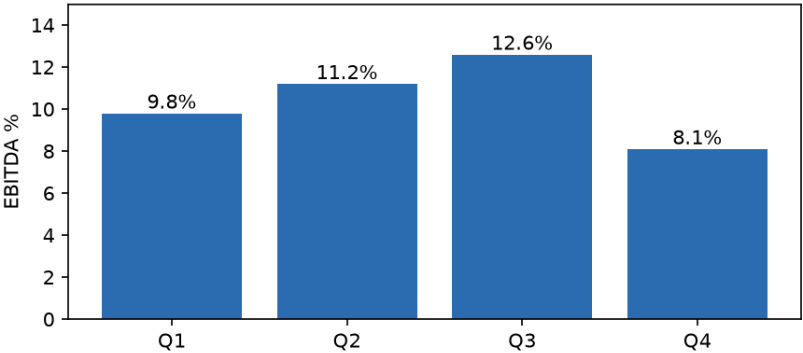

In [6]:
for table in doc.tables:
    display(table.export_to_dataframe(doc=doc))

for picture in doc.pictures:
    display(picture.get_image(doc))

### Multimodalny RAG: wyszukiwanie w tekście, tabelach i obrazach

Używamy wzorca **multi-vector**:
1. każdy element dostaje **tekstową reprezentację do wyszukiwania** – fragment tekstu jest nią sam, tabela dostaje streszczenie od LLM, a rysunek opis przygotowany przez model wizyjny,
2. baza wektorowa przechowuje tę reprezentację, a w metadanych **oryginalny element** (tabelę w Markdown, obraz w base64),
3. po wyszukaniu model dostaje oryginał – także sam obraz – a nie streszczenie.

Dzięki temu odpowiedź opiera się na źródle i nie ogranicza jej streszczenie, które pominęło szczegół.

In [7]:
import base64
import io

from langchain_core.documents import Document
from langchain_core.messages import HumanMessage
from langchain_text_splitters import MarkdownHeaderTextSplitter


def image_to_b64(pil_image) -> str:
    buffer = io.BytesIO()
    pil_image.save(buffer, format="PNG")
    return base64.b64encode(buffer.getvalue()).decode()


def describe_image(b64: str) -> str:
    message = HumanMessage(content=[
        {"type": "text", "text": "Opisz po polsku ten rysunek z raportu finansowego na potrzeby wyszukiwania. "
                                 "Podaj tytuł, osie, każdą etykietę danych z wartością i główny trend."},
        {"type": "image", "base64": b64, "mime_type": "image/png"},
    ])
    return llm.invoke([message]).content


def summarize_table(table_md: str) -> str:
    return llm.invoke(f"Streść po polsku tę tabelę na potrzeby wyszukiwania. Wymień nazwy wszystkich wierszy i kolumn.\n\n{table_md}").content


elements = []

# 1) tekst: podział według nagłówków, każdy fragment zachowuje swoją sekcję w metadanych
text_md = doc.export_to_markdown(image_placeholder="")
for chunk in MarkdownHeaderTextSplitter([("#", "h1"), ("##", "section")]).split_text(text_md):
    elements.append(Document(page_content=chunk.page_content,
                             metadata={**chunk.metadata, "kind": "text", "raw": chunk.page_content}))

# 2) tabele: streszczenie do wyszukiwania, Markdown jako oryginał
for table in doc.tables:
    table_md = table.export_to_markdown(doc=doc)
    elements.append(Document(page_content=summarize_table(table_md), metadata={"kind": "table", "raw": table_md}))

# 3) rysunki: opis od modelu wizyjnego do wyszukiwania, obraz jako oryginał
for picture in doc.pictures:
    b64 = image_to_b64(picture.get_image(doc))
    elements.append(Document(page_content=describe_image(b64), metadata={"kind": "image", "raw": b64}))

for element in elements:
    print(f"[{element.metadata['kind']}] {element.page_content[:120]!r}")

[text] 'Nordwind Logistics S.A. to grupa logistyczna z siedzibą w Gdańsku, założona w 2009 roku. Prowadzi transport drogowy, spe'
[text] 'W 2025 roku przychody wzrosły o 4,4% do 802 mln zł, a zysk netto spadł do 31 mln zł (2024: 38 mln zł) z powodu wyższych '
[text] 'Wzrost zapewniły transport drogowy i magazynowanie; spedycja morska spadła po zakończeniu dużego kontraktu ze skandynaws'
[text] 'Koszty operacyjne wzrosły do 741 mln zł. Koszty osobowe stanowiły 31%, a paliwo 28% kosztów operacyjnych. Kwartalną marż'
[text] 'Akcjonariusze: Anna Kowalska 34%, Amber Holdings Ltd 26%, Piotr Nowak 15%, free float 25%. Anna Kowalska jest również pr'
[text] 'Zarząd wskazuje ryzyka rynkowe i operacyjne opisane poniżej.'
[text] 'Około 41% przychodów jest fakturowanych w EUR, więc grupa jest narażona na zmiany kursu EUR/PLN. Grupa zabezpiecza 60% o'
[text] 'Głównym ryzykiem operacyjnym jest niedobór zawodowych kierowców; rotacja kierowców wyniosła w 2025 roku 18%. Przepisy un'
[table] '**Tabela 1.

In [8]:
from langchain_core.vectorstores import InMemoryVectorStore

mm_store = InMemoryVectorStore.from_documents(elements, embeddings)


def multimodal_rag(question: str, k: int = 3) -> str:
    hits = mm_store.similarity_search(question, k=k)
    content = [{"type": "text", "text": "Odpowiedz na pytanie wyłącznie na podstawie poniższych źródeł. "
                                        "Wskaż rodzaj źródła (tekst, tabela lub rysunek).\n\n"
                                        f"PYTANIE: {question}"}]
    for hit in hits:
        if hit.metadata["kind"] == "image":
            content.append({"type": "image", "base64": hit.metadata["raw"], "mime_type": "image/png"})
        else:
            content.append({"type": "text", "text": f"[{hit.metadata['kind']}]\n{hit.metadata['raw']}"})
    print("znalezione:", [hit.metadata["kind"] for hit in hits])
    return llm.invoke([HumanMessage(content=content)]).content


print(multimodal_rag("W którym kwartale 2025 roku marża EBITDA była najniższa i ile wynosiła?"))
print()
print(multimodal_rag("Który segment urósł najbardziej w 2025 roku w wartościach bezwzględnych?"))

znalezione: ['text', 'image', 'text']
Najniższa marża EBITDA była w **IV kwartale 2025 roku** i wynosiła **8,1%**.

Źródło: rysunek.

znalezione: ['table', 'text', 'text']
Najbardziej wzrosło **magazynowanie** — o 25 mln zł, ze 129 mln zł w 2024 r. do 154 mln zł w 2025 r.

Rodzaj źródła: **tabela**.


Odpowiedź na pierwsze pytanie istnieje tylko jako piksele na wykresie. RAG oparty wyłącznie na tekście z `PyPDFLoader` zobaczyłby zdanie *„Kwartalną marżę EBITDA przedstawia Rysunek 1”* i nic więcej.

### ColPali: wyszukiwanie całych stron po ich obrazie

Powyższy pipeline nadal najpierw zamienia wszystko na tekst. **ColPali** ([publikacja](https://arxiv.org/abs/2407.01449)) całkowicie pomija parsowanie: model wizyjno-językowy (PaliGemma, a w ColQwen – Qwen2-VL) zamienia **obraz każdej strony** na zbiór wektorów dla fragmentów obrazu, a zapytanie jest do nich dopasowywane token po tokenie (*late interaction*, jak w ColBERT). Układ strony, tabele, wykresy i logotypy są przeszukiwane bezpośrednio, a obraz znalezionej strony trafia do multimodalnego LLM.

| | Docling + multi-vector | ColPali |
|---|---|---|
| indeks | tekst, streszczenia tabel, opisy obrazów | obrazy stron (≈1000 wektorów na stronę) |
| parsowanie / OCR | potrzebne | niepotrzebne |
| sprzęt | wystarczy CPU | zalecane GPU |
| wynik | konkretny element | cała strona |

Wymaga GPU i pobiera model o rozmiarze ok. 6 GB, dlatego pokazujemy tylko kod. [Byaldi](https://github.com/AnswerDotAI/byaldi) zamyka go w kilku liniach:

```python
# pip install byaldi
from byaldi import RAGMultiModalModel

retriever = RAGMultiModalModel.from_pretrained("vidore/colqwen2-v1.0")
retriever.index(input_path=PDF_PATH, index_name="nordwind", store_collection_with_index=True)
results = retriever.search("najniższa kwartalna marża EBITDA", k=1)
page_b64 = results[0].base64  # wyślij obraz tej strony do LLM, tak jak w multimodal_rag()
```

## Część 2. GraphRAG: pytania o relacje

Syntetyczny zbiór danych w stylu rejestru spółek (KRS, Companies House): spółki, osoby, udziały i miejsca w zarządach. Każdy fakt to osobny krótki dokument, tak jak w odpisie z rejestru albo w serwisie informacyjnym.

Pytanie: **Które spółki są pośrednio powiązane z Anną Kowalską poprzez wspólnych udziałowców?**

Aby odpowiedzieć, trzeba (1) znaleźć spółki, w których Anna ma udziały, (2) znaleźć ich *pozostałych* udziałowców, (3) znaleźć spółki, w których udziały mają *ci* udziałowcy. To ścieżka o długości 3 i żaden pojedynczy dokument jej nie zawiera.

In [9]:
# (udziałowiec, spółka, % udziałów) – udziałowcem może być osoba lub spółka
OWNS = [
    ("Anna Kowalska", "Nordwind Logistics S.A.", 34),
    ("Amber Holdings Ltd", "Nordwind Logistics S.A.", 26),
    ("Piotr Nowak", "Nordwind Logistics S.A.", 15),
    ("Anna Kowalska", "Vistula Capital S.A.", 51),
    ("Granite Ventures LP", "Vistula Capital S.A.", 49),
    ("Amber Holdings Ltd", "Baltic Freight sp. z o.o.", 70),
    ("Piotr Nowak", "Orion Tech sp. z o.o.", 60),
    ("Granite Ventures LP", "Polar Foods S.A.", 22),
    ("Maria Wiśniewska", "Polar Foods S.A.", 40),
    ("Jan Zieliński", "Silesia Steel S.A.", 80),
]
# (osoba, spółka, funkcja)
BOARD = [
    ("Anna Kowalska", "Nordwind Logistics S.A.", "przewodnicząca rady nadzorczej"),
    ("Maria Wiśniewska", "Polar Foods S.A.", "prezes zarządu"),
    ("Jan Zieliński", "Orion Tech sp. z o.o.", "członek zarządu"),
    ("Ewa Lewandowska", "Baltic Freight sp. z o.o.", "prezes zarządu"),
]
PEOPLE = {"Anna Kowalska", "Piotr Nowak", "Maria Wiśniewska", "Jan Zieliński", "Ewa Lewandowska"}

facts = [f"{s} posiada {p}% udziałów w spółce {c}." for s, c, p in OWNS]
facts += [f"{person} pełni funkcję: {role} w spółce {company}." for person, company, role in BOARD]
# dystraktor: bardzo podobny do pytania, ale to nie jest powiązanie właścicielskie
facts.append("W wywiadzie Anna Kowalska pochwaliła wyniki Silesia Steel S.A. i nazwała ją wzorcową spółką.")
facts

['Anna Kowalska posiada 34% udziałów w spółce Nordwind Logistics S.A..',
 'Amber Holdings Ltd posiada 26% udziałów w spółce Nordwind Logistics S.A..',
 'Piotr Nowak posiada 15% udziałów w spółce Nordwind Logistics S.A..',
 'Anna Kowalska posiada 51% udziałów w spółce Vistula Capital S.A..',
 'Granite Ventures LP posiada 49% udziałów w spółce Vistula Capital S.A..',
 'Amber Holdings Ltd posiada 70% udziałów w spółce Baltic Freight sp. z o.o..',
 'Piotr Nowak posiada 60% udziałów w spółce Orion Tech sp. z o.o..',
 'Granite Ventures LP posiada 22% udziałów w spółce Polar Foods S.A..',
 'Maria Wiśniewska posiada 40% udziałów w spółce Polar Foods S.A..',
 'Jan Zieliński posiada 80% udziałów w spółce Silesia Steel S.A..',
 'Anna Kowalska pełni funkcję: przewodnicząca rady nadzorczej w spółce Nordwind Logistics S.A..',
 'Maria Wiśniewska pełni funkcję: prezes zarządu w spółce Polar Foods S.A..',
 'Jan Zieliński pełni funkcję: członek zarządu w spółce Orion Tech sp. z o.o..',
 'Ewa Lewandowska

### Punkt odniesienia: klasyczny RAG wektorowy

In [10]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

QUESTION = "Które spółki są pośrednio powiązane z Anną Kowalską poprzez wspólnych udziałowców?"

fact_store = InMemoryVectorStore.from_texts(facts, embeddings)
retriever = fact_store.as_retriever(search_kwargs={"k": 4})

rag_prompt = ChatPromptTemplate.from_template(
    "Odpowiedz wyłącznie na podstawie kontekstu. Jeśli kontekst nie wystarcza, powiedz to.\n\nKONTEKST:\n{context}\n\nPYTANIE: {question}"
)
retrieved = retriever.invoke(QUESTION)
print("Znalezione fakty:", *[f"  - {d.page_content}" for d in retrieved], sep="\n")
print()
print((rag_prompt | llm | StrOutputParser()).invoke({"context": "\n".join(d.page_content for d in retrieved), "question": QUESTION}))

Znalezione fakty:
  - Anna Kowalska posiada 51% udziałów w spółce Vistula Capital S.A..
  - Anna Kowalska posiada 34% udziałów w spółce Nordwind Logistics S.A..
  - W wywiadzie Anna Kowalska pochwaliła wyniki Silesia Steel S.A. i nazwała ją wzorcową spółką.
  - Anna Kowalska pełni funkcję: przewodnicząca rady nadzorczej w spółce Nordwind Logistics S.A..

Kontekst nie zawiera informacji o wspólnych udziałowcach, więc nie pozwala ustalić takich spółek.


Retriever zwraca fakty, które *wspominają Annę* – łącznie z dystraktorem – ale nie fakty o Amber Holdings, Piotrze Nowaku i Granite Ventures, które **w ogóle jej nie wspominają**. A to właśnie te kroki są potrzebne do odpowiedzi. Zwiększenie `k` nie rozwiązuje problemu w ogólnym przypadku: w prawdziwym rejestrze z milionami faktów drugi i trzeci krok nigdy nie są podobne do pytania.

### Graf wiedzy + agent

Te same fakty umieszczamy w grafie (`networkx`, w pamięci) i dajemy agentowi jedno narzędzie: *pokaż relacje encji*. Agent przechodzi po grafie krok po kroku, tak jak zrobiłby to analityk.

In [11]:
import networkx as nx
from langchain.agents import create_agent
from langchain_core.tools import tool

G = nx.MultiDiGraph()
for shareholder, company, pct in OWNS:
    G.add_edge(shareholder, company, rel="OWNS", pct=pct)
for person, company, role in BOARD:
    G.add_edge(person, company, rel="BOARD_MEMBER", role=role)
for node in G:
    G.nodes[node]["type"] = "Person" if node in PEOPLE else "Company"


@tool
def entity_relations(name: str) -> str:
    """Zwraca wszystkie relacje osoby lub spółki w grafie powiązań (w obu kierunkach)."""
    if name not in G:
        matches = [n for n in G if name.lower() in n.lower()]
        return f"Nieznana encja. Czy chodziło o: {matches}?"
    lines = [f"{name} ({G.nodes[name]['type']})"]
    for _, target, attrs in G.out_edges(name, data=True):
        lines.append(f"  -[{attrs['rel']} {attrs.get('pct', attrs.get('role', ''))}]-> {target}")
    for source, _, attrs in G.in_edges(name, data=True):
        lines.append(f"  <-[{attrs['rel']} {attrs.get('pct', attrs.get('role', ''))}]- {source}")
    return "\n".join(lines)


graph_agent = create_agent(
    llm,
    tools=[entity_relations],
    system_prompt="Odpowiadasz na pytania o graf powiązań właścicielskich spółek. Eksploruj go narzędziem krok po kroku. "
                  "Krawędzie OWNS łączą udziałowców ze spółkami. W końcowej odpowiedzi wymień każdą spółkę wraz ze "
                  "ścieżką, która ją łączy, np. Osoba -> Spółka A <- Udziałowiec -> Spółka B. Odpowiadaj po polsku.",
)

result = graph_agent.invoke({"messages": [{"role": "user", "content": QUESTION}]})
for message in result["messages"]:
    if message.type == "ai" and message.tool_calls:
        print("🔧", [call["args"]["name"] for call in message.tool_calls])
print(result["messages"][-1].content)

🔧 ['Anna Kowalska']
🔧 ['Nordwind Logistics S.A.', 'Vistula Capital S.A.']
🔧 ['Amber Holdings Ltd', 'Piotr Nowak', 'Granite Ventures LP']
🔧 ['Baltic Freight sp. z o.o.', 'Orion Tech sp. z o.o.', 'Polar Foods S.A.']
🔧 ['Maria Wiśniewska']
[{'type': 'text', 'text': 'Anna Kowalska jest pośrednio powiązana poprzez wspólnych udziałowców z trzema spółkami:\n\n- **Baltic Freight sp. z o.o.**: Anna Kowalska → Nordwind Logistics S.A. ← Amber Holdings Ltd → Baltic Freight sp. z o.o.\n- **Orion Tech sp. z o.o.**: Anna Kowalska → Nordwind Logistics S.A. ← Piotr Nowak → Orion Tech sp. z o.o.\n- **Polar Foods S.A.**: Anna Kowalska → Vistula Capital S.A. ← Granite Ventures LP → Polar Foods S.A.\n\nStrzałki wskazują kierunek relacji właścicielskiej: od udziałowca do spółki.', 'annotations': [], 'id': 'msg_0d3d732cd9c9fbda006b098ad8e9b487d28126b8eaedc8253d', 'phase': 'final_answer'}]


Dla stałego typu pytania LLM nie jest nawet potrzebny do przejścia po grafie – zapytanie grafowe daje dokładną odpowiedź, która jest też dobrą **wartością referencyjną** do oceny agenta:

In [12]:
def linked_via_common_shareholders(person: str) -> set[tuple[str, str, str]]:
    owns = lambda node: {c for _, c, a in G.out_edges(node, data=True) if a["rel"] == "OWNS"}
    owners = lambda company: {s for s, _, a in G.in_edges(company, data=True) if a["rel"] == "OWNS"}
    return {(target, co_owner, shared)
            for shared in owns(person)
            for co_owner in owners(shared) - {person}
            for target in owns(co_owner) - owns(person)}


expected = linked_via_common_shareholders("Anna Kowalska")
assert {t for t, _, _ in expected} == {"Baltic Freight sp. z o.o.", "Orion Tech sp. z o.o.", "Polar Foods S.A."}
for target, co_owner, shared in sorted(expected):
    print(f"{target:28} przez {co_owner} (współudziałowiec w {shared})")

Baltic Freight sp. z o.o.    przez Amber Holdings Ltd (współudziałowiec w Nordwind Logistics S.A.)
Orion Tech sp. z o.o.        przez Piotr Nowak (współudziałowiec w Nordwind Logistics S.A.)
Polar Foods S.A.             przez Granite Ventures LP (współudziałowiec w Vistula Capital S.A.)


### Neo4j + Cypher (opcjonalnie)

W produkcji graf przechowuje się w grafowej bazie danych. [Neo4j](https://neo4j.com/) odpytuje się językiem **Cypher**, w którym ścieżka o wielu krokach to jeden wzorzec. `GraphCypherQAChain` z `langchain-neo4j` pozwala, by LLM **sam napisał zapytanie Cypher** na podstawie schematu grafu (*text-to-Cypher*), wykonał je i sformułował odpowiedź.

Uruchom lokalnie Neo4j i ustaw zmienne (np. w `.env`); bez nich poniższe komórki zostaną pominięte:
```bash
docker run -d --name neo4j -p 7474:7474 -p 7687:7687 -e NEO4J_AUTH=neo4j/password123 -e NEO4J_PLUGINS='["apoc"]' neo4j:5
# .env: NEO4J_URI=bolt://localhost:7687  NEO4J_USERNAME=neo4j  NEO4J_PASSWORD=password123
```
Darmowa alternatywa w chmurze: [Neo4j AuraDB Free](https://neo4j.com/product/auradb/).

In [24]:
import os

from langchain_neo4j import GraphCypherQAChain, Neo4jGraph

neo4j_graph = None
if os.getenv("NEO4J_URI"):
    neo4j_graph = Neo4jGraph()  # czyta NEO4J_URI, NEO4J_USERNAME, NEO4J_PASSWORD
    neo4j_graph.query("MATCH (n) DETACH DELETE n")  # zaczynamy od pustej bazy demonstracyjnej
    neo4j_graph.query("""
        UNWIND $owns AS row
        MERGE (s:Entity {name: row[0]})
        MERGE (c:Entity {name: row[1]})
        MERGE (s)-[:OWNS {pct: row[2]}]->(c)""", {"owns": OWNS})
    neo4j_graph.query("""
        UNWIND $board AS row
        MERGE (p:Entity {name: row[0]})
        MERGE (c:Entity {name: row[1]})
        MERGE (p)-[:BOARD_MEMBER {role: row[2]}]->(c)""", {"board": BOARD})
    neo4j_graph.query("MATCH (e:Entity) WHERE e.name IN $people SET e:Person", {"people": list(PEOPLE)})
    neo4j_graph.query("MATCH (e:Entity) WHERE NOT e:Person SET e:Company")
    neo4j_graph.refresh_schema()
    print(neo4j_graph.schema)
else:
    print("Brak NEO4J_URI – pomijam komórki z Neo4j.")

Node properties:
Entity {name: STRING}
Person {name: STRING}
Company {name: STRING}
Relationship properties:
OWNS {pct: INTEGER}
BOARD_MEMBER {role: STRING}
The relationships:
(:Entity)-[:BOARD_MEMBER]->(:Entity)
(:Entity)-[:BOARD_MEMBER]->(:Company)
(:Entity)-[:OWNS]->(:Entity)
(:Entity)-[:OWNS]->(:Company)
(:Person)-[:BOARD_MEMBER]->(:Entity)
(:Person)-[:BOARD_MEMBER]->(:Company)
(:Person)-[:OWNS]->(:Entity)
(:Person)-[:OWNS]->(:Company)
(:Company)-[:OWNS]->(:Entity)
(:Company)-[:OWNS]->(:Company)


Całe pytanie o 3 krokach jako jeden wzorzec Cypher:

In [25]:
CYPHER = """
MATCH (p:Person {name: $name})-[:OWNS]->(shared:Company)<-[:OWNS]-(co_owner)-[:OWNS]->(target:Company)
WHERE co_owner <> p AND NOT (p)-[:OWNS]->(target)
RETURN target.name AS company, co_owner.name AS via, shared.name AS shared_company
ORDER BY company
"""
if neo4j_graph:
    for row in neo4j_graph.query(CYPHER, {"name": "Anna Kowalska"}):
        print(row)

{'company': 'Baltic Freight sp. z o.o.', 'via': 'Amber Holdings Ltd', 'shared_company': 'Nordwind Logistics S.A.'}
{'company': 'Orion Tech sp. z o.o.', 'via': 'Piotr Nowak', 'shared_company': 'Nordwind Logistics S.A.'}
{'company': 'Polar Foods S.A.', 'via': 'Granite Ventures LP', 'shared_company': 'Vistula Capital S.A.'}


I text-to-Cypher: zapytanie pisze LLM. `allow_dangerous_requests=True` jest wymagane, ponieważ wygenerowane zapytanie mogłoby też modyfikować dane – w produkcji łącz się użytkownikiem bazy **tylko do odczytu**.

In [26]:
if neo4j_graph:
    cypher_chain = GraphCypherQAChain.from_llm(
        llm, graph=neo4j_graph, verbose=True, validate_cypher=True, allow_dangerous_requests=True
    )
    print(cypher_chain.invoke({"query": QUESTION})["result"])



> Entering new GraphCypherQAChain chain...
Generated Cypher:
MATCH (anna:Person {name: 'Anna Kowalska'})-[:OWNS]->(company:Company)<-[:OWNS]-(shareholder)-[:OWNS]->(related:Company)
WHERE related <> company
RETURN DISTINCT related.name AS company

Full Context:
[{'company': 'Polar Foods S.A.'}, {'company': 'Orion Tech sp. z o.o.'}, {'company': 'Baltic Freight sp. z o.o.'}]

> Finished chain.
Spółki pośrednio powiązane z Anną Kowalską poprzez wspólnych udziałowców to Polar Foods S.A., Orion Tech sp. z o.o. oraz Baltic Freight sp. z o.o.


### Microsoft GraphRAG i inne podejścia

Powyżej mieliśmy gotowy graf. Przy nieustrukturyzowanym tekście graf trzeba najpierw **zbudować za pomocą LLM**:
- [Microsoft GraphRAG](https://github.com/microsoft/graphrag) wydobywa z dokumentów encje i relacje, grupuje je w **społeczności** (algorytm Leiden) i pisze streszczenie każdej z nich. *Local search* odpowiada na pytania o konkretne encje; *global search* odpowiada na pytania o cały zbiór („jakie są główne tematy?”) na podstawie streszczeń społeczności – czego wyszukiwanie top-k w bazie wektorowej w ogóle nie potrafi.
- `LLMGraphTransformer` (`langchain-experimental`) zamienia obiekty `Document` na węzły i relacje, które `Neo4jGraph.add_graph_documents()` ładuje do Neo4j.
- [LightRAG](https://github.com/HKUDS/LightRAG) to tańsza alternatywa łącząca wyszukiwanie w grafie i w bazie wektorowej.

Budowa grafu przez LLM jest **kosztowna** (kilka wywołań na fragment), a błędy ekstrakcji zostają w grafie na stałe – dane, które już są ustrukturyzowane (rejestry, CRM, ERP), ładuj bezpośrednio, tak jak tutaj.

## Część 3. Vectorless RAG: PageIndex

[PageIndex](https://github.com/VectifyAI/PageIndex) zastępuje indeks wektorowy **hierarchicznym spisem treści** dokumentu – drzewem sekcji z krótkimi streszczeniami. Zamiast wyszukiwania podobieństwa LLM **rozumuje na drzewie**, tak jak człowiek korzysta ze spisu treści: wybiera rozdział, potem podrozdział i czyta tylko ten fragment.

```
Nordwind Logistics S.A. – Raport roczny 2025
├── 1. Informacje o przedsiębiorstwie
├── 2. Wyniki finansowe
│   ├── 2.1. Przychody
│   └── 2.2. Koszty
├── 3. Struktura własnościowa
└── 4. Czynniki ryzyka
    ├── 4.1. Ryzyka rynkowe
    └── 4.2. Ryzyka operacyjne
```

Zalety: brak chunkingu, który tnie sekcje w połowie, brak embeddingów i **możliwa do prześledzenia** odpowiedź – widać, które sekcje model wybrał i dlaczego. Wady: każde pytanie kosztuje dodatkowe wywołanie LLM na drzewie, a metoda działa tylko dla dokumentów o wyraźnej strukturze. Traktuj ją jako mocną opcję dla długich dokumentów finansowych i prawnych, a nie uniwersalnego następcę RAG wektorowego.

Poniżej minimalna implementacja tej idei. Drzewo budujemy z dokumentu Docling z części 1.

In [16]:
import re

from docling_core.types.doc import SectionHeaderItem, TableItem, TextItem

# 1) walk the Docling document and attach content to the last heading
sections, current = [], None
for item, _ in doc.iterate_items():
    if isinstance(item, SectionHeaderItem) and (match := re.match(r"(\d+(?:\.\d+)*)\.?\s+(.*)", item.text)):
        current = {"node_id": match.group(1), "title": item.text, "text": ""}
        sections.append(current)
    elif current and isinstance(item, TableItem):
        current["text"] += item.export_to_markdown(doc=doc) + "\n"
    elif current and isinstance(item, TextItem):
        current["text"] += item.text + "\n"

# 2) build the tree from the numbering: "2.1" is a child of "2"
by_id = {s["node_id"]: {**s, "nodes": []} for s in sections}
tree = []
for node_id, node in by_id.items():
    parent = node_id.rpartition(".")[0]
    (by_id[parent]["nodes"] if parent in by_id else tree).append(node)


def print_tree(nodes, indent=""):
    for node in nodes:
        print(f"{indent}[{node['node_id']}] {node['title']}")
        print_tree(node["nodes"], indent + "    ")


print_tree(tree)

[1] 1. Informacje o przedsiębiorstwie
[2] 2. Wyniki finansowe
    [2.1] 2.1. Przychody
    [2.2] 2.2. Koszty
[3] 3. Struktura własnościowa
[4] 4. Czynniki ryzyka
    [4.1] 4.1. Ryzyka rynkowe
    [4.2] 4.2. Ryzyka operacyjne


PageIndex przechowuje w każdym węźle krótkie **streszczenie**, aby model mógł podjąć decyzję bez czytania pełnego tekstu. Generujemy je jednym wywołaniem wsadowym:

In [17]:
summaries = llm.batch([f"Streść jednym zdaniem po polsku, czego dotyczy ta sekcja raportu:\n\n{node['text']}"
                       for node in by_id.values()])
for node, summary in zip(by_id.values(), summaries):
    node["summary"] = summary.content


def tree_for_llm(nodes) -> list[dict]:
    """Drzewo bez pełnych tekstów – tylko to widzi model podczas wyszukiwania."""
    return [{"node_id": n["node_id"], "title": n["title"], "summary": n["summary"], "nodes": tree_for_llm(n["nodes"])}
            for n in nodes]

**Przeszukiwanie drzewa** zwraca ustrukturyzowany wynik (Pydantic + `with_structured_output`): uzasadnienie i listę węzłów do przeczytania. Następnie **generowanie odpowiedzi** dostaje pełny tekst tylko tych sekcji.

In [18]:
import json

from pydantic import BaseModel, Field


class TreeSearch(BaseModel):
    thinking: str = Field(description="Które sekcje prawdopodobnie zawierają odpowiedź i dlaczego")
    node_ids: list[str] = Field(description="Identyfikatory najbardziej szczegółowych węzłów do przeczytania")


tree_search_prompt = ChatPromptTemplate.from_template(
    "Masz pytanie i spis treści dokumentu ze streszczeniem każdej sekcji.\n"
    "Znajdź sekcje, które prawdopodobnie zawierają odpowiedź. Uzasadnienie napisz po polsku.\n\n"
    "PYTANIE: {question}\n\nDRZEWO DOKUMENTU:\n{tree}"
)
answer_prompt = ChatPromptTemplate.from_template(
    "Odpowiedz na pytanie wyłącznie na podstawie tych sekcji raportu. Podaj numery sekcji.\n\n"
    "{sections}\n\nPYTANIE: {question}"
)
tree_searcher = tree_search_prompt | llm.with_structured_output(TreeSearch)


def pageindex_rag(question: str) -> str:
    search = tree_searcher.invoke({"question": question, "tree": json.dumps(tree_for_llm(tree), ensure_ascii=False, indent=1)})
    print("🧭", search.thinking)
    print("📖 czytam:", [by_id[i]["title"] for i in search.node_ids if i in by_id])
    sections_text = "\n\n".join(f"## {by_id[i]['title']}\n{by_id[i]['text']}" for i in search.node_ids if i in by_id)
    return (answer_prompt | llm | StrOutputParser()).invoke({"sections": sections_text, "question": question})


print(pageindex_rag("Jaka część przychodów jest narażona na ryzyko walutowe i jak spółka się przed nim chroni?"))

🧭 Sekcja 4.1 bezpośrednio dotyczy ryzyka walutowego i sposobów jego ograniczania, więc najprawdopodobniej zawiera zarówno udział narażonych przychodów, jak i opis zabezpieczeń.
📖 czytam: ['4.1. Ryzyka rynkowe']
Około **41% przychodów** jest fakturowanych w EUR i narażonych na zmiany kursu EUR/PLN. Grupa zabezpiecza **60% oczekiwanej pozycji netto w EUR** za pomocą 12-miesięcznych kontraktów forward. **(Sekcja 4.1)**


Słowo *walutowe* nie występuje w raporcie (jest tam *kurs EUR/PLN*), a pytanie dotyczy dwóch faktów naraz. Model znalazł sekcję 4.1 dzięki **rozumowaniu** o strukturze („ryzyko walutowe → czynniki ryzyka → ryzyka rynkowe”), a nie przez zgodność słów.

Pytanie wymagające kilku sekcji:

In [19]:
print(pageindex_rag("Dlaczego zysk netto spadł, choć przychody wzrosły, i któremu segmentowi poszło gorzej?"))

🧭 Sekcja 2 wskazuje przyczynę spadku zysku netto mimo wzrostu przychodów. Sekcja 2.2 może zawierać szczegóły wzrostu kosztów, a sekcja 2.1 wskazuje segment, którego przychody spadły.
📖 czytam: ['2. Wyniki finansowe', '2.1. Przychody', '2.2. Koszty']
Zysk netto spadł z 38 mln zł do 31 mln zł mimo wzrostu przychodów z powodu wyższych kosztów osobowych i paliwa (sekcje **2 i 2.2**).

Gorzej poszło **spedycji morskiej**: jej przychody spadły z 251 mln zł do 236 mln zł po zakończeniu dużego kontraktu ze skandynawską siecią handlową (sekcja **2.1**).


Oficjalny [PageIndex](https://github.com/VectifyAI/PageIndex) buduje drzewo bezpośrednio z PDF (również dla dokumentów bez numerowanych nagłówków, z zakresami stron w każdym węźle) i jest dostępny jako pakiet open source, hostowane API i serwer MCP. Autorzy rozwijają też wyszukiwanie oparte na obrazach stron, bez OCR – w tym samym kierunku co ColPali, ale bez wektorów.

## Podsumowanie: który RAG kiedy?

| Podejście | Indeks | Mocna strona | Słaba strona |
|---|---|---|---|
| RAG wektorowy | embeddingi fragmentów | wiele krótkich, niezależnych dokumentów; nieprecyzyjne, semantyczne pytania | tabele/wykresy, relacje wieloetapowe, długie ustrukturyzowane dokumenty |
| Docling + multimodalny RAG | tekst + streszczenia tabel + opisy obrazów | PDF z tabelami i wykresami | koszt opisania każdego obrazu |
| ColPali | wektory fragmentów obrazów stron | skany, slajdy, strony bogate wizualnie, bez parsowania | GPU, duży indeks, wynik na poziomie całej strony |
| GraphRAG / Neo4j | graf wiedzy | relacje, ścieżki, agregacje, pytania typu „połącz kropki” | budowa grafu z tekstu jest kosztowna |
| PageIndex (vectorless) | drzewo dokumentu ze streszczeniami | długie, ustrukturyzowane dokumenty finansowe i prawne; wyjaśnialność | dodatkowe wywołanie LLM na pytanie, wymaga struktury |

W praktyce te wzorce się **łączy**: np. agent ma retriever wektorowy, narzędzie Cypher i narzędzie przeszukiwania drzewa, i sam wybiera, które pasuje do pytania (zob. `8_4_LangGraph_RAG`).